# UVmap reanalysis

Minimal updates to `20241118_UVmap-Diana(1).ipynb` for the local uv environment. The analysis cell order, classification rules and plotting styles are retained. Unused helper functions and imports have been removed. Changes: local paths, explicit CSV alignment and validation, pandas compatibility, read-only disk-backed expression, separate figure outputs, omitted 3D plotting, optional t-SNE, and CNR2 and ROR1 plots.

Run from the `CDS1-2` directory using its `.venv` kernel. Expression is used as supplied, matching the original notebook; no new normalization is applied.


In [1]:
from pathlib import Path

import scanpy as sc
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt


In [2]:
sc.set_figure_params(dpi=100, dpi_save = 300, color_map = 'viridis_r')
sc.settings.verbosity = 1
#sc.logging.print_header()
plt.rcParams['pdf.fonttype'] = 42
sc.settings.figdir = 'figures'
Path(sc.settings.figdir).mkdir(parents=True, exist_ok=True)

In [3]:
import matplotlib as mpl
# https://github.com/theislab/scanpy/issues/1720
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [4]:
%load_ext autoreload
%autoreload 2

## Load Input (Processed scRNA-seq data)

In [5]:
## Use input from gdrive (downloaded locally)
# https://drive.google.com/file/d/1-aWa10ct86mHpfFyoaDgX-v3SJIofFSt/view?usp=sharing
# Read expression from disk to limit memory use on a laptop.
adata = sc.read_h5ad('UVmap_Sathya_annotated.h5ad', backed='r')
# Backed mode still loads layers; release the unused duplicate count layer.
# This only changes the Python object, not the read-only source file.
del adata.layers['counts']
adata


AnnData object with n_obs × n_vars = 264624 × 31795 backed at 'UVmap_Sathya_annotated.h5ad'
    obs: 'Author', 'Sample', 'Method', 'Platform', 'GEX', 'Stage', 'Patient', 'Age', 'Sex', 'CellType', 'Tissue', 'CellType_indepth', 'gs_prediction', 'predCNA', 'celltype_assigned', 'leiden', 'predictions', 'leiden_1', 'leiden_1.2', 'leiden_1.5', 'annotation_level_0', 'annotation_level_1', 'annotation_level_2', 'annotation_level_3'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'Author_colors', 'CellType_colors', 'Patient_colors', 'Platform_colors', 'Sample_colors', 'Stage_colors', 'Tissue_colors', 'annotation_level_1_colors', 'annotation_level_2_colors', 'annotation_level_3_colors', 'leiden', 'leiden_1.2_colors', 'leiden_1.5_colors', 'leiden_1_colors', 'neighbors', 'predictions_colors', 'umap'
    obsm: 'X_umap'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

## GEP and PRAME classification

In [6]:
#UCell score from UVmap
PRAME_UCell = pd.read_csv('UVmap_UCell_PRAME.csv', index_col=0).iloc[:, 0]
Class1_UCell = pd.read_csv('UVmap_UCell_Class1.csv', index_col=0).iloc[:, 0]
Class2_UCell = pd.read_csv('UVmap_UCell_Class2.csv', index_col=0).iloc[:, 0]
Control_UCell = pd.read_csv('UVmap_UCell_Control.csv', index_col=0).iloc[:, 0]

In [7]:
adata.obs.index = adata.obs['Author'].astype(str) + str('_') +  adata.obs.index.astype(str) 

In [8]:
# Align by cell identifier, rather than row position.
for scores in [PRAME_UCell, Class1_UCell, Class2_UCell, Control_UCell]:
    assert adata.obs_names.is_unique and scores.index.is_unique
    assert adata.obs_names.difference(scores.index).empty, 'Missing UCell scores'

adata.obs['PRAME_UCell'] = PRAME_UCell
adata.obs['Class1_UCell'] = Class1_UCell
adata.obs['Class2_UCell'] = Class2_UCell
adata.obs['Control_UCell'] = Control_UCell
assert adata.obs[['PRAME_UCell', 'Class1_UCell', 'Class2_UCell', 'Control_UCell']].notna().all().all()


In [9]:
# Define the initial conditions for malignant cell classification
conditions_initial = [
    (adata.obs['annotation_level_1'] == 'Malignant_cell') & (adata.obs['Control_UCell'] > 0.2) & (adata.obs['Class1_UCell'] > 0.2),
    (adata.obs['annotation_level_1'] == 'Malignant_cell') & (adata.obs['Control_UCell'] > 0.2) & (adata.obs['Class2_UCell'] > 0.2),
    (adata.obs['annotation_level_1'] == 'Malignant_cell') & (adata.obs['Control_UCell'] > 0.2) & (adata.obs['Class1_UCell'] <= 0.2) & (adata.obs['Class2_UCell'] <= 0.2)
]

choices_initial = ['Malignant_cell_Class1', 'Malignant_cell_Class2', 'Malignant_cell']

# Create a new column with the initial classification
adata.obs['malignant_classification'] = np.select(conditions_initial, choices_initial, default=adata.obs['annotation_level_1'])

# Define conditions for PRAME classification within Class1 and Class2
conditions_prame = [
    (adata.obs['malignant_classification'] == 'Malignant_cell_Class1') & (adata.obs['PRAME_UCell'] > 0.2),
    (adata.obs['malignant_classification'] == 'Malignant_cell_Class1') & (adata.obs['PRAME_UCell'] <= 0.2),
    (adata.obs['malignant_classification'] == 'Malignant_cell_Class2') & (adata.obs['PRAME_UCell'] > 0.2),
    (adata.obs['malignant_classification'] == 'Malignant_cell_Class2') & (adata.obs['PRAME_UCell'] <= 0.2)
]

choices_prame = ['Malignant_cell_Class1_PRAME+', 'Malignant_cell_Class1_PRAME-', 'Malignant_cell_Class2_PRAME+', 'Malignant_cell_Class2_PRAME-']

# Update the malignant_classification column with PRAME classifications
adata.obs['malignant_classification'] = np.select(conditions_prame, choices_prame, default=adata.obs['malignant_classification'])

# Display the updated DataFrame
#print(adata.obs[['annotation_level_1', 'Control_UCell', 'Class1_UCell', 'Class2_UCell', 'PRAME_UCell', 'malignant_classification']])

In [10]:
specific_values = ['Malignant_cell_Class1_PRAME+', 'Malignant_cell_Class1_PRAME-', 
                   'Malignant_cell_Class2_PRAME+', 'Malignant_cell_Class2_PRAME-', 
                   'Malignant_cell']

# Update 'malignant_classification' to copy from 'annotation_level_3' if not in specific values
adata.obs['malignant_classification'] = np.where(
    adata.obs['malignant_classification'].isin(specific_values),
    adata.obs['malignant_classification'],
    adata.obs['annotation_level_3']
)

In [11]:
adata.obs['malignant_classification'] = (
    adata.obs['malignant_classification'].astype('category')
)
adata.obs['malignant_classification'].value_counts()


malignant_classification
Malignant_cell                       98999
Photoreceptor_cell                   35065
T_cell                               32720
Macrophage                           17686
NK_cell                               9571
Fibroblast                            9230
Bipolar_neuron                        8414
Epithelial_cell                       8374
Mueller_cell                          6987
Endothelial_cell                      6461
CAF                                   5596
Malignant_cell_Class2_PRAME-          4008
Melanocyte                            3838
RPE_cell                              3595
Malignant_cell_Class1_PRAME-          3301
Ciliary_muscle_cell                   1847
Plasma_cell                           1666
Pigmented_ciliary_epithelial_cell     1544
Mature_cone_cell                      1432
Cholangiocyte                         1301
B_cell                                1287
Schwann_cell                           774
Malignant_cell_Class1_PRAME+ 

In [12]:
adata.obs['malignant_classification'] = adata.obs['malignant_classification'].cat.reorder_categories(
    [

    
'Malignant_cell',
'Malignant_cell_Class1_PRAME+',
'Malignant_cell_Class1_PRAME-',
'Malignant_cell_Class2_PRAME+',
'Malignant_cell_Class2_PRAME-',


'Photoreceptor_cell',
'Mature_cone_cell',
'Bipolar_neuron',
'Mueller_cell',
'Schwann_cell',
'T_cell',
'NK_cell',
'B_cell',
'Plasma_cell',
'Macrophage',
'Mast_cell',
'pDC',
'RPE_cell',
'Melanocyte',
'Epithelial_cell',
'Pigmented_ciliary_epithelial_cell',
'Ciliary_muscle_cell',
'Hepatocyte',
'Cholangiocyte',
'Fibroblast',
'CAF',
'Myofibroblast',
'Endothelial_cell',

  
])

## Figure 5A_Top

/var/folders/83/kzvdm7nx1zd5n15q9zlz1pc00000gn/T/ipykernel_73720/1938147839.py:11: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(adata, color='malignant_classification',


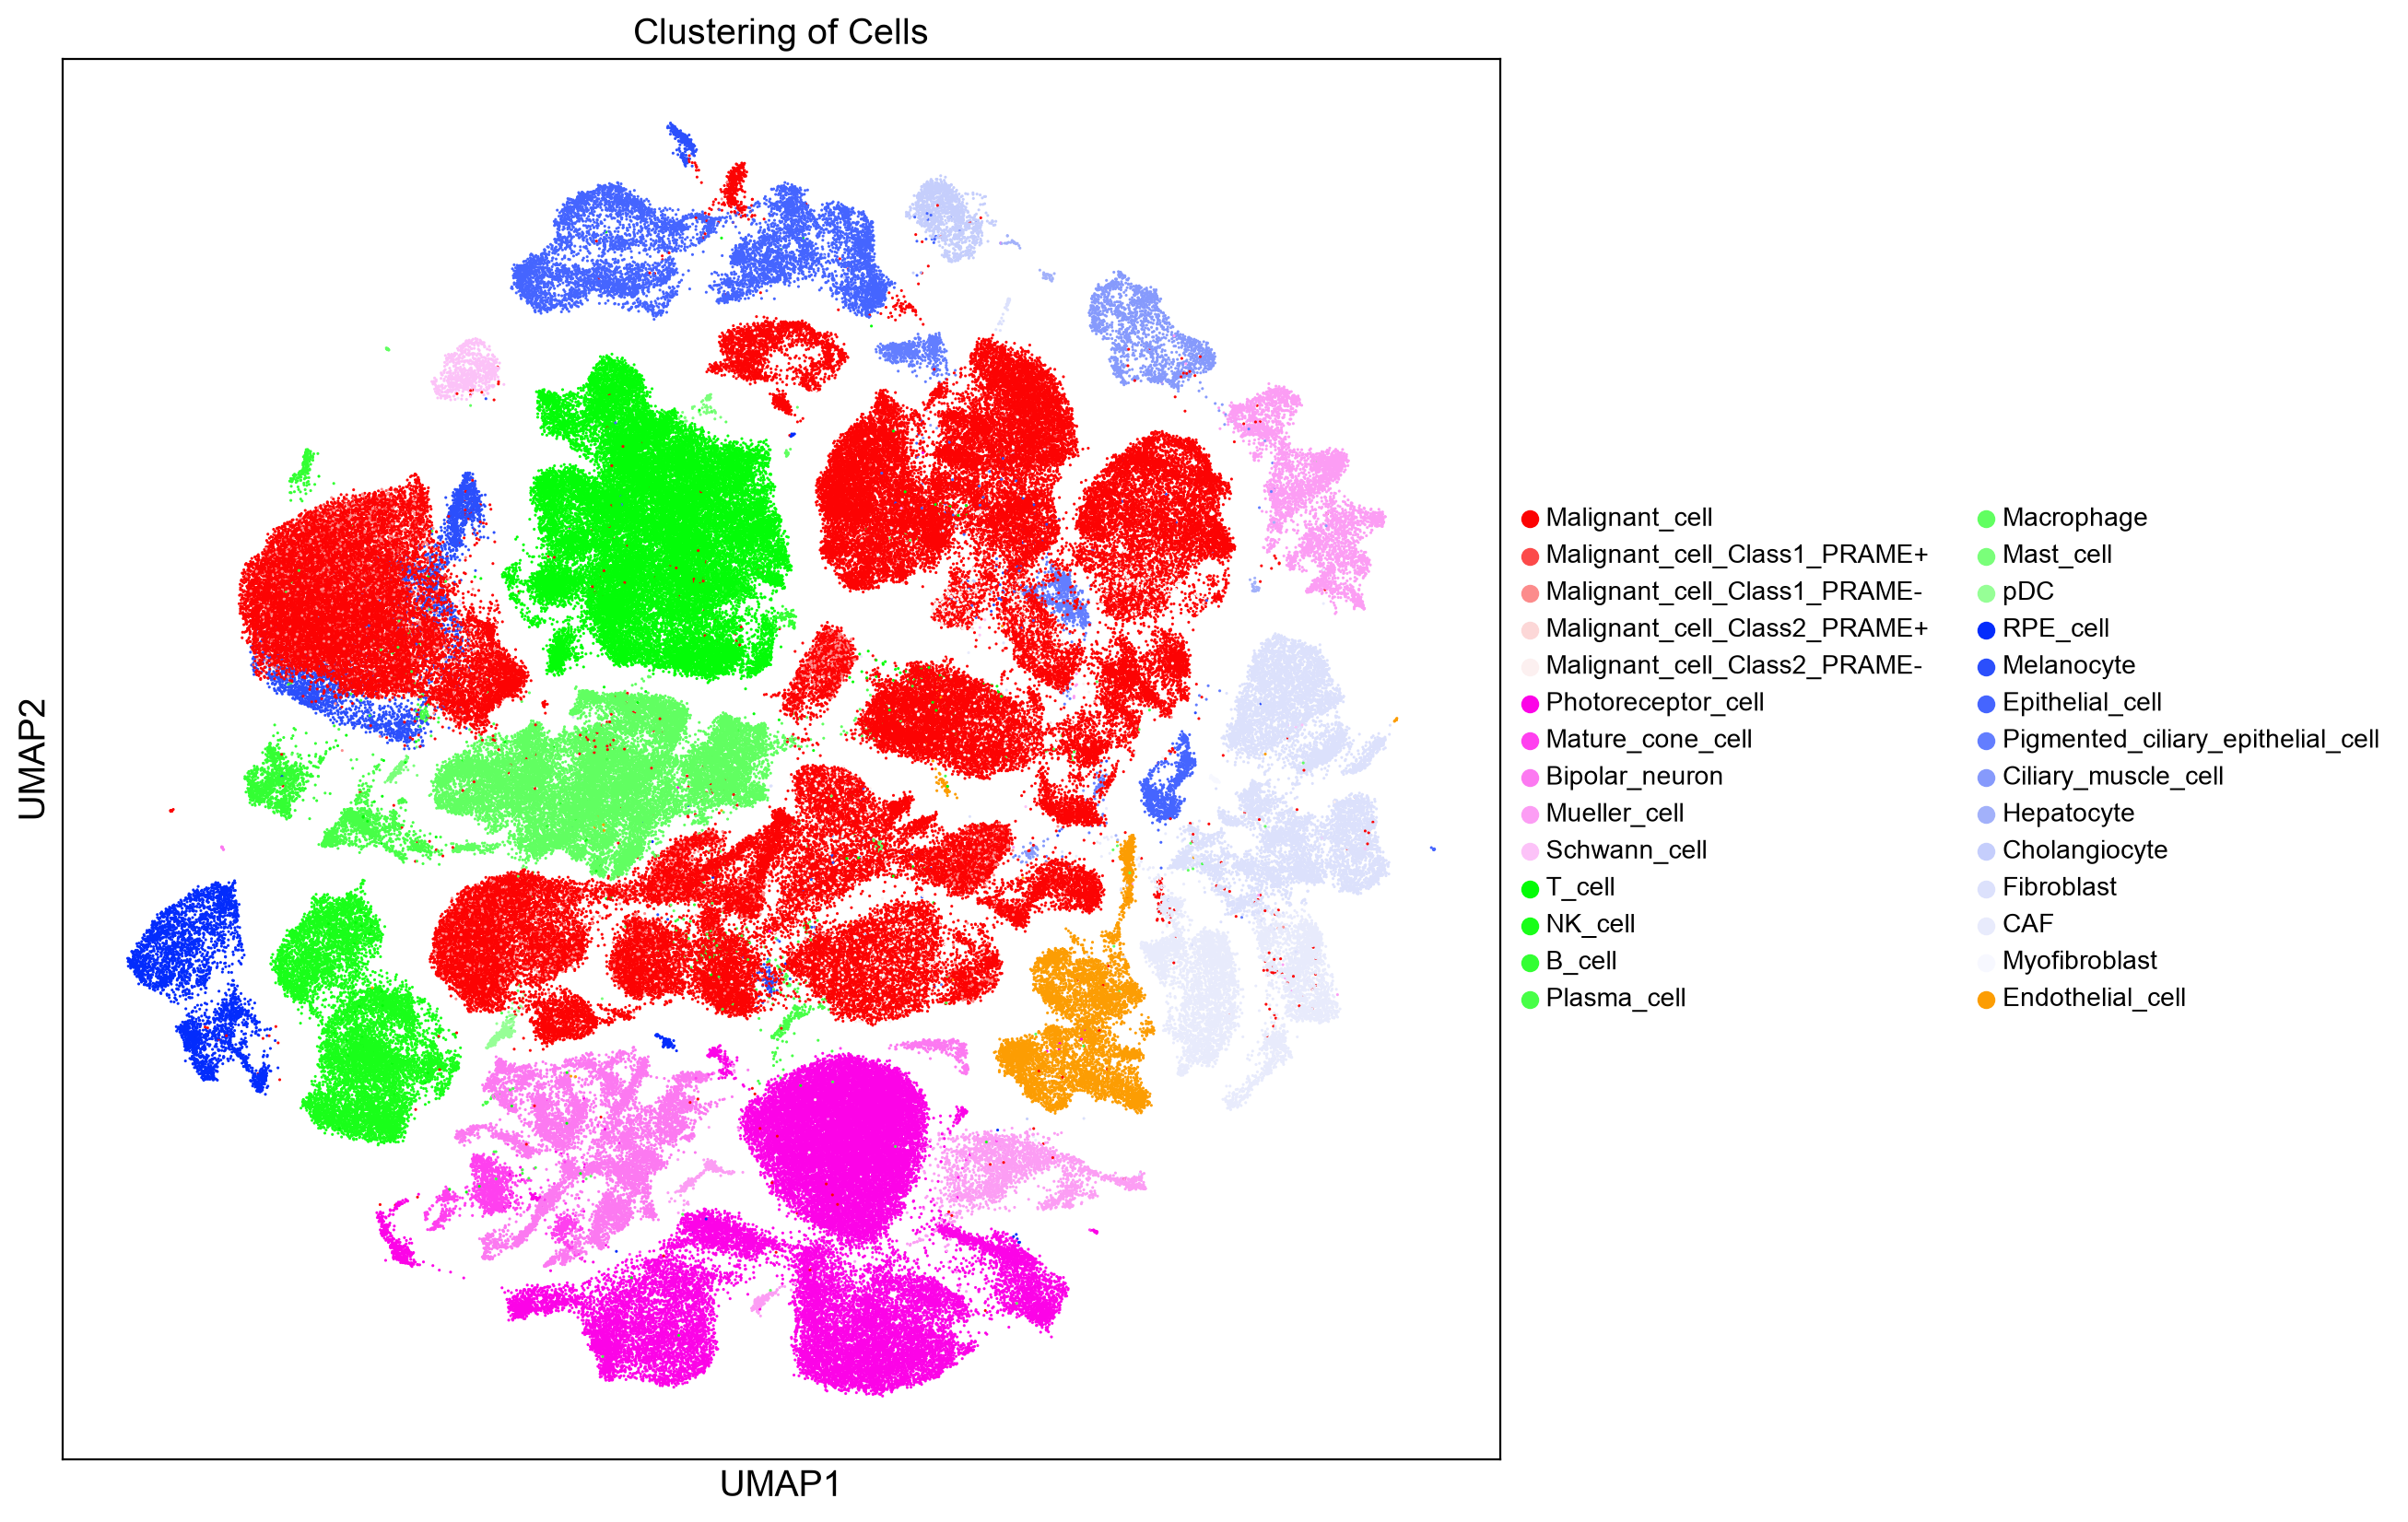

In [13]:
# Inital setting for plot size
from matplotlib import rcParams

FIGSIZE = (10, 10)
rcParams["figure.figsize"] = FIGSIZE

# Create a figure and axes object
fig, ax = plt.subplots()

# Generate the UMAP plot on the specified axes
sc.pl.umap(adata, color='malignant_classification', 
           legend_fontoutline=5, frameon=True,  # Enable axes
           title='Clustering of Cells', size=5, 
           add_outline=False, legend_loc='right margin', 
           legend_fontsize=10, ax=ax, show=True,
palette=[    
    '#fc0303',
    '#fc4a4a',
    '#fc8c8c',
    '#fcd7d7',
    '#fcf0f0',
    
    '#fc03e7',
    '#ff40ef',
    '#fc79f1',
    '#fc9df4',
    '#fcc2f8',
    #'#ffe6fd',
    
    '#03fc07',
    '#19ff19',
    '#33ff33',
    '#47ff47',
    '#61ff61',
    '#7aff7a',
    '#96ff96',
    #'#adffad',
    #'#c4ffc4',
    #'#d7fcd7',
    #'#edffed',
    
    '#032cfc',
    '#2b4ffc',
    '#4565ff',
    '#637eff',
    '#869afc',
    '#a2b1fa',
    '#c5cefc',
    '#dce1fc',
    '#e8ebfc',
    '#f7f8ff',
    
    
    '#fc9d03'
           ],save=True)

# Customize the axes with labels
ax.set_xlabel('UMAP1')  # Label for x-axis
ax.set_ylabel('UMAP2')  # Label for y-axis

plt.show()

## Option2: 3D UMAP omitted

The supplied atlas contains two UMAP coordinates, so the original 3D plotting code cannot run on this object.


In [14]:
# 3D plotting removed; use the original 2D UMAP above.


## Option3: optional t-SNE

Set `RUN_TSNE = True` below to calculate the alternative embedding. It is disabled by default for laptop runs and is not needed for Figure 5A or gene-expression plots.


In [15]:
RUN_TSNE = False

if RUN_TSNE:
    # t-SNE needs an in-memory matrix; retain X but omit the unused counts layer.
    tsne_adata = adata.to_memory()
    
    # Compute t-SNE (if not already computed)
    sc.tl.tsne(tsne_adata, n_pcs=50, perplexity=30)  # Adjust n_pcs and perplexity as needed
    
    # Create a figure and axes object
    fig, ax = plt.subplots(figsize=(8, 6))
    
    # Plot t-SNE, coloring by 'malignant_classification'
    sc.pl.tsne(tsne_adata, color='malignant_classification', 
               legend_fontoutline=5, frameon=True,  # Enable axes
               title='t-SNE Clustering of Cells', size=5, 
               add_outline=False, legend_loc='right margin', 
               legend_fontsize=10, ax=ax, show=True,
    palette=[    
        '#fc0303',
        '#fc4a4a',
        '#fc8c8c',
        '#fcd7d7',
        '#fcf0f0',
        
        '#fc03e7',
        '#ff40ef',
        '#fc79f1',
        '#fc9df4',
        '#fcc2f8',
        #'#ffe6fd',
        
        '#03fc07',
        '#19ff19',
        '#33ff33',
        '#47ff47',
        '#61ff61',
        '#7aff7a',
        '#96ff96',
        #'#adffad',
        #'#c4ffc4',
        #'#d7fcd7',
        #'#edffed',
        
        '#032cfc',
        '#2b4ffc',
        '#4565ff',
        '#637eff',
        '#869afc',
        '#a2b1fa',
        '#c5cefc',
        '#dce1fc',
        '#e8ebfc',
        '#f7f8ff',
        
        
        '#fc9d03'
               ],save=True)
    
    # Add axis labels
    ax.set_xlabel('t-SNE1')
    ax.set_ylabel('t-SNE2')
    
    # Display the plot
    plt.show()
    adata.obsm['X_tsne'] = tsne_adata.obsm['X_tsne'].copy()
    del tsne_adata
else:
    print('Optional t-SNE skipped; set RUN_TSNE = True to run it.')


Optional t-SNE skipped; set RUN_TSNE = True to run it.


In [16]:
adata.obs['annotation_level_1'] = adata.obs['annotation_level_1'].cat.reorder_categories(
    [
'Malignant_cell',
'Neuron-Glia',
'Immune_cell',
'Epithelial_cell',
'Endothelial_cell'
  
])

## Figure 5A_Bottom

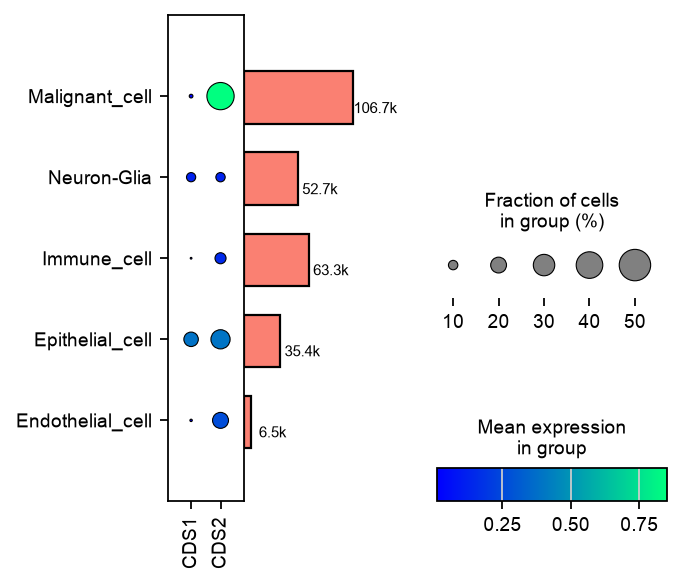

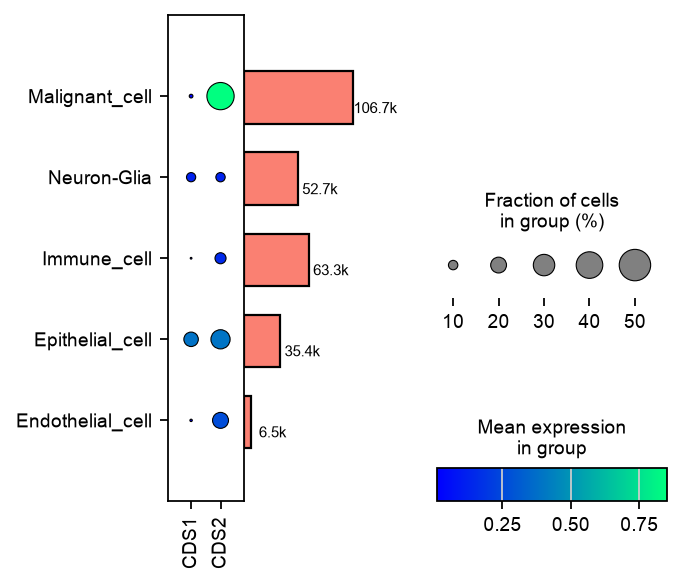

In [17]:
markers = ['CDS1', 'CDS2']

# Set figure parameters
sc.set_figure_params(scanpy=True, fontsize=10)

# Keep the blue-to-green colormap shown in the original saved output.
# Generate the dotplot with adjusted figure size and get the figure object
dp = sc.pl.dotplot(adata, markers, 'annotation_level_1', figsize=(4,4), cmap='winter', return_fig=True)

# Customize the dotplot
dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()

# Save the dotplot to a file
#dp.savefig('dotplot.png')  # Save as PNG
dp.savefig(Path(sc.settings.figdir) / 'dotplot.pdf')  # Save as PDF (optional)

## Explore individual genes

Run the function definition below, then call `analyse_gene(adata, 'ROR1')` with any gene symbol present in the atlas. Each call displays a dot plot and cell-type tables, saves the plot and five summary CSVs in `figures/`, and returns the tables. An optional `output_dir` selects another output directory.


In [18]:
def analyse_gene(adata, gene, output_dir=None):
    """Plot one gene and return cell-type, stage, study and sample summaries.

    Uses the supplied expression matrix and UVmap annotation columns.
    Files are written to output_dir, defaulting to sc.settings.figdir.
    """
    if gene not in adata.var_names:
        raise ValueError(f'{gene!r} is absent from this atlas.')

    output_dir = Path(sc.settings.figdir if output_dir is None else output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    dp = sc.pl.dotplot(adata, [gene], 'annotation_level_1',
                       figsize=(4,4), cmap='winter', return_fig=True)
    dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()
    dp.savefig(output_dir / f'dotplot_{gene}.pdf')

    # Quantify detection using the same expression values as the plot.
    expression = adata[:, [gene]].X
    values = expression.toarray().ravel() if sp.issparse(expression) else np.asarray(expression).ravel()
    gene_obs = adata.obs.copy()
    gene_obs['expression'] = values
    gene_obs['detected'] = values > 0
    summaries = {}

    for groupby, name in [
        (['annotation_level_1'], 'broad'),
        (['annotation_level_3'], 'detailed'),
        (['Stage', 'annotation_level_3'], 'stage_detailed'),
        (['Author', 'annotation_level_1'], 'study_broad'),
        (['Stage', 'Sample', 'annotation_level_1'], 'sample_broad'),
    ]:
        summary = gene_obs.groupby(groupby, observed=True).agg(
            cells=('expression', 'size'), detected=('detected', 'sum'),
            mean_expression=('expression', 'mean'))
        summary['percent_detected'] = 100 * summary['detected'] / summary['cells']
        summary.to_csv(output_dir / f'{gene}_{name}.csv')
        summaries[name] = summary
        if len(groupby) == 1:
            display(summary.sort_values('percent_detected', ascending=False))

    return summaries


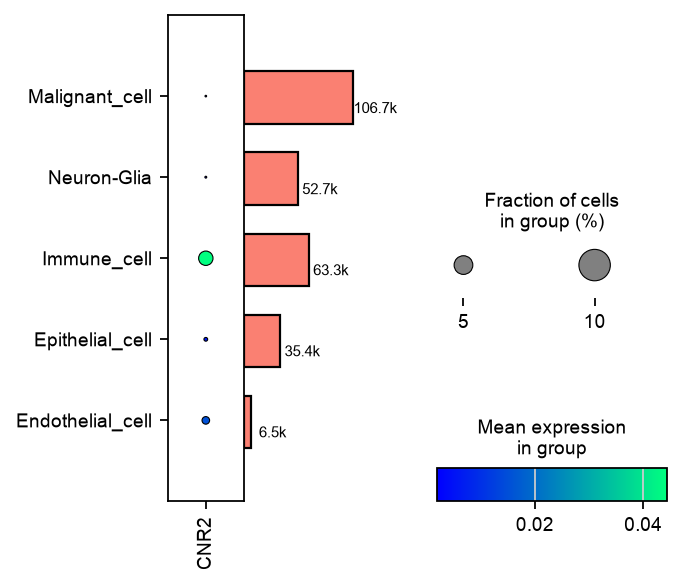

,cells,detected,mean_expression,percent_detected
annotation_level_1,,,,
Immune_cell,63333,2233,0.044353,3.525808
Endothelial_cell,6461,97,0.015477,1.501316
Epithelial_cell,35438,207,0.006236,0.584119
Neuron-Glia,52672,122,0.002335,0.231622
Malignant_cell,106720,204,0.001987,0.191154


,cells,detected,mean_expression,percent_detected
annotation_level_3,,,,
B_cell,1287,384,0.442113,29.836830
NK_cell,9571,1158,0.151813,12.099049
pDC,253,15,0.090909,5.928854
Myofibroblast,30,1,0.033333,3.333333
T_cell,32720,544,0.018582,1.662592
Endothelial_cell,6461,97,0.015477,1.501316
Cholangiocyte,1301,12,0.009224,0.922367
Epithelial_cell,8374,58,0.008240,0.692620
Macrophage,17686,121,0.008029,0.684157


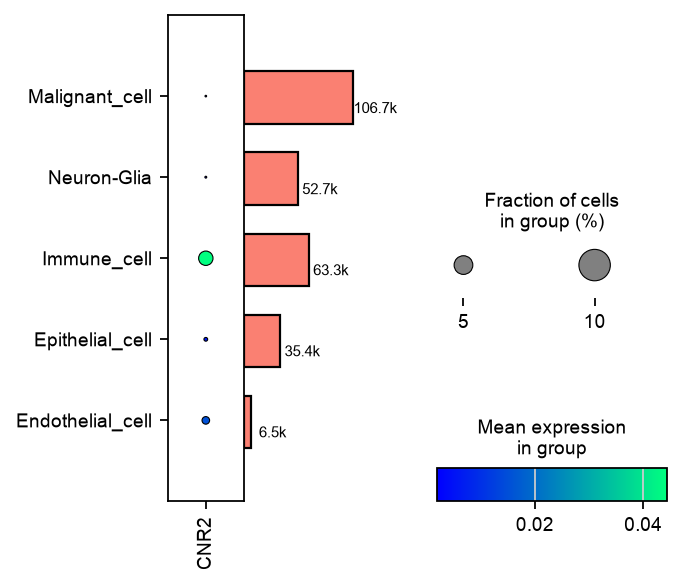

In [19]:
cnr2_summaries = analyse_gene(adata, 'CNR2')


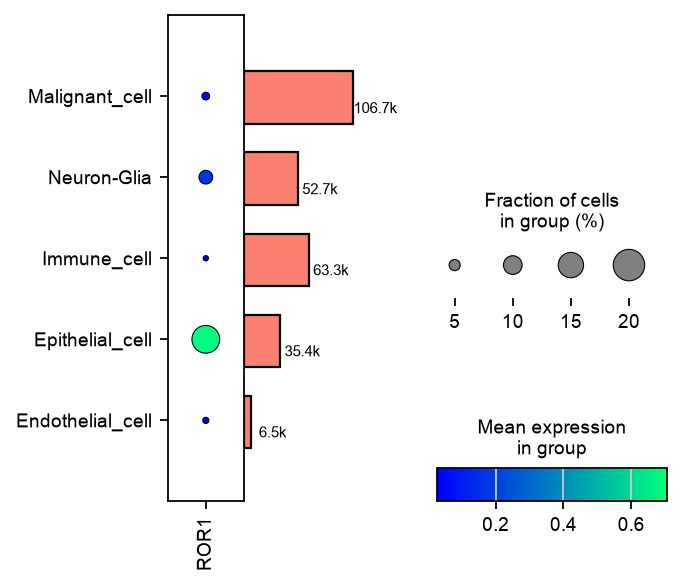

,cells,detected,mean_expression,percent_detected
annotation_level_1,,,,
Epithelial_cell,35438,6002,0.704921,16.936622
Neuron-Glia,52672,3475,0.167907,6.597433
Malignant_cell,106720,3289,0.051228,3.081897
Endothelial_cell,6461,146,0.032967,2.259712
Immune_cell,63333,1178,0.027663,1.860010


,cells,detected,mean_expression,percent_detected
annotation_level_3,,,,
Ciliary_muscle_cell,1847,1573,5.629128,85.165133
Pigmented_ciliary_epithelial_cell,1544,870,2.408031,56.347150
Schwann_cell,774,318,0.941860,41.085271
CAF,5596,1985,1.443174,35.471766
Mueller_cell,6987,2320,0.967654,33.204523
Cholangiocyte,1301,145,0.142967,11.145273
Fibroblast,9230,899,0.175623,9.739978
Bipolar_neuron,8414,583,0.130021,6.928928
Epithelial_cell,8374,440,0.104729,5.254359


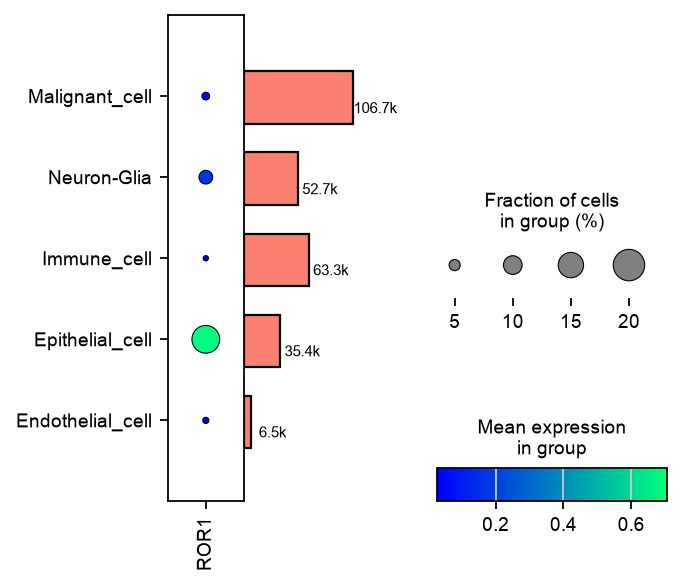

In [20]:
ror1_summaries = analyse_gene(adata, 'ROR1')
